## Preguntas guía:

- ¿Cómo difiere el flete relativo entre destinos metropolitanos y no metropolitanos de un mismo estado?
- ¿En qué municipios aumenta más la proporción de entregas tardías en semanas de alta demanda?

#### Vínculo con el Caso 1

En el primer caso estudiamos dónde se concentraban los pedidos y cómo variaban la facturación y el flete entre estados. En el Caso 2 combinamos facturación y flete para comparar el peso del envío entre destinos metropolitanos y no metropolitanos de un mismo estado. También retomamos el volumen de pedidos, ahora por semana, para ver en qué municipios aumentan los atrasos durante los períodos de alta demanda.

## 1. Punto de partida

**Predicción.** El flete relativo y la diferencia entre la fecha real y la prometida podrían revelar diferencias entre municipios de un mismo estado.

**Decisión y justificación.** Partimos de los CSV curados del Caso 1. Conservamos la marca `en_poblacion` para medir la cobertura geográfica sobre todos los pedidos y sobre la población de análisis.


Ejecutar desde la raíz del proyecto con las dependencias de `requirements.txt` y los CSV curados en `data/curated`.

In [1]:
from pathlib import Path
import os

import pandas as pd

curados = Path("data/curated")
pedidos = pd.read_csv(curados / "pedidos_curados.csv")
geolocalizacion = pd.read_csv(
    curados / "geolocation_curada.csv",
    dtype={"geolocation_zip_code_prefix": "string", "geolocation_lng": "string"},
)

assert len(pedidos) == 99_441
assert pedidos["order_id"].notna().all() and pedidos["order_id"].is_unique
assert not geolocalizacion.duplicated().any()

print(f"Pedidos curados: {len(pedidos):,}")
print(f"Registros de geolocalización: {len(geolocalizacion):,}")

Pedidos curados: 99,441
Registros de geolocalización: 738,332


### 1.1 Controles heredados del caso 1

Se ejecutan los mismos controles del caso 1 antes del enriquecimiento. En los CSV originales se comprueban claves primarias y foráneas e importes de ítems. En `pedidos_curados.csv` se comprueban el grano, las 99.441 filas, los estados informados y las reglas de la población. Convertimos la fecha de compra en una copia para aplicar el control sobre el CSV.

In [2]:
carpeta_olist = Path(os.environ.get("OLIST_DATA_DIR", "data/olist")).expanduser()
if not carpeta_olist.is_dir() and "OLIST_DATA_DIR" not in os.environ:
    import kagglehub

    carpeta_olist = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))

archivos_control = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
}
raw_control = {
    tabla: pd.read_csv(carpeta_olist / archivo)
    for tabla, archivo in archivos_control.items()
}

N_PEDIDOS = 99_441
ESTADO_POBLACION = "delivered"
FECHA_INICIO = pd.Timestamp("2017-01-01")
FECHA_FIN = pd.Timestamp("2018-09-01")  # excluyente
pedidos_control = pedidos.assign(
    order_purchase_timestamp=pd.to_datetime(
        pedidos["order_purchase_timestamp"], format="mixed", errors="coerce"
    )
)

def controlar_fuente(datos):
    # Claves primarias únicas
    assert datos["orders"]["order_id"].is_unique, "orders: order_id repetido"
    assert datos["customers"]["customer_id"].is_unique, "customers: customer_id repetido"
    assert datos["products"]["product_id"].is_unique, "products: product_id repetido"
    assert datos["sellers"]["seller_id"].is_unique, "sellers: seller_id repetido"
    assert not datos["order_items"].duplicated(["order_id", "order_item_id"]).any(), \
        "order_items: (order_id, order_item_id) repetido"
    assert not datos["order_payments"].duplicated(["order_id", "payment_sequential"]).any(), \
        "order_payments: (order_id, payment_sequential) repetido"

    # Claves foráneas sin huérfanos
    assert datos["orders"]["customer_id"].isin(datos["customers"]["customer_id"]).all(), \
        "orders -> customers: hay clientes inexistentes"
    assert datos["order_items"]["order_id"].isin(datos["orders"]["order_id"]).all(), \
        "order_items -> orders: hay pedidos inexistentes"
    assert datos["order_items"]["product_id"].isin(datos["products"]["product_id"]).all(), \
        "order_items -> products: hay productos inexistentes"
    assert datos["order_items"]["seller_id"].isin(datos["sellers"]["seller_id"]).all(), \
        "order_items -> sellers: hay vendedores inexistentes"
    assert datos["order_payments"]["order_id"].isin(datos["orders"]["order_id"]).all(), \
        "payments -> orders: hay pedidos inexistentes"
    assert datos["order_reviews"]["order_id"].isin(datos["orders"]["order_id"]).all(), \
        "reviews -> orders: hay pedidos inexistentes"

    # Validez de importes
    assert (datos["order_items"]["price"] > 0).all(), "order_items: price <= 0"
    assert (datos["order_items"]["freight_value"] >= 0).all(), "order_items: freight_value negativo"


def controlar_tabla_analitica(df):
    # Grano: 1 fila por pedido, sin perder ni duplicar pedidos
    assert len(df) == N_PEDIDOS, f"Se esperaban {N_PEDIDOS} filas y hay {len(df)}"
    assert df["order_id"].is_unique, "Hay pedidos repetidos"

    # Todos los pedidos tienen un estado válido
    assert df["state_name"].notna().all(), "Hay pedidos sin estado o con un estado desconocido"

    # Reglas de la población
    poblacion = df[df["en_poblacion"]]
    assert (poblacion["order_status"] == ESTADO_POBLACION).all(), "Entró un pedido no entregado"
    assert (poblacion["facturacion"] > 0).all(), "Entró un pedido sin facturación"
    assert (poblacion["costo_envio"] >= 0).all(), "Entró un costo de envío negativo"
    assert poblacion["order_purchase_timestamp"].between(FECHA_INICIO, FECHA_FIN, inclusive="left").all(), \
        "Entró un pedido fuera de la ventana"


controlar_fuente(raw_control)
controlar_tabla_analitica(pedidos_control)
print("Todos los controles del Caso 1 pasan.")
del raw_control, pedidos_control

Todos los controles del Caso 1 pasan.


## 2. Recuperación del prefijo postal

**Decisión y justificación.** Obtuviimos el prefijo postal desde la tabla original de clientes mediante `customer_id`. Leemos solo las columnas necesarias y validamos que la unión conserve una fila por pedido.


In [3]:
clientes = pd.read_csv(
    carpeta_olist / "olist_customers_dataset.csv",
    usecols=["customer_id", "customer_zip_code_prefix"],
    dtype={"customer_zip_code_prefix": "string"},
)
clientes["customer_zip_code_prefix"] = clientes["customer_zip_code_prefix"].str.zfill(5)

pedidos_con_prefijo = pedidos.merge(clientes, on="customer_id", how="left", validate="many_to_one")
assert len(pedidos_con_prefijo) == len(pedidos) and pedidos_con_prefijo["order_id"].is_unique
print("Pedidos sin prefijo postal:", pedidos_con_prefijo["customer_zip_code_prefix"].isna().sum())

Pedidos sin prefijo postal: 0


## 3. Coordenada aproximada por prefijo y estado

**Decisión y justificación.** Calculamos la mediana de latitud y longitud por prefijo postal y estado. Así obtenemos un punto representativo sin multiplicar pedidos y reducimos la influencia de coordenadas extremas. Una longitud del CSV tiene el sufijo `en`. Convertimos las coordenadas a números y excluimos del cálculo las filas no numéricas, faltantes o fuera del rango global.

**Límite.** El punto representa al prefijo postal y puede caer en otro municipio si el prefijo abarca más de uno. 

In [4]:
geolocalizacion["geolocation_zip_code_prefix"] = geolocalizacion["geolocation_zip_code_prefix"].str.zfill(5)
for columna in ["geolocation_lat", "geolocation_lng"]:
    geolocalizacion[columna] = pd.to_numeric(geolocalizacion[columna], errors="coerce")

valida = (
    geolocalizacion["geolocation_lat"].between(-90, 90)
    & geolocalizacion["geolocation_lng"].between(-180, 180)
).fillna(False)
print("Puntos excluidos por coordenadas inválidas:", (~valida).sum())

coordenadas_por_prefijo = (
    geolocalizacion.loc[valida]
    .groupby(["geolocation_zip_code_prefix", "geolocation_state"], as_index=False)
    .agg(latitud=("geolocation_lat", "median"), longitud=("geolocation_lng", "median"))
    .rename(columns={
        "geolocation_zip_code_prefix": "customer_zip_code_prefix",
        "geolocation_state": "customer_state",
    })
)
pedidos_con_coordenadas = pedidos_con_prefijo.merge(
    coordenadas_por_prefijo,
    on=["customer_zip_code_prefix", "customer_state"],
    how="left",
    validate="many_to_one",
)
assert len(pedidos_con_coordenadas) == len(pedidos)
assert pedidos_con_coordenadas["order_id"].is_unique

con_coordenadas = pedidos_con_coordenadas[["latitud", "longitud"]].notna().all(axis=1)
print(f"Pedidos con coordenadas: {con_coordenadas.sum():,} / {len(pedidos):,} ({con_coordenadas.mean():.2%})")
cobertura = con_coordenadas[pedidos_con_coordenadas["en_poblacion"]]
print(f"Cobertura en la población: {cobertura.sum():,} / {len(cobertura):,} ({cobertura.mean():.2%})")

Puntos excluidos por coordenadas inválidas: 1
Pedidos con coordenadas: 99,163 / 99,441 (99.72%)
Cobertura en la población: 95,947 / 96,211 (99.73%)


## 4. Cruce espacial con municipios

**Decisión y justificación.** Usamos la malla municipal de 2018 por su cercanía al período de los pedidos. Construimos los puntos con longitud en X y latitud en Y, interpretadas como WGS 84 (EPSG:4326), y los reproyectamos al CRS declarado en la malla. Cruzamos con `within` una sola vez por prefijo y estado y trasladamos el resultado a los pedidos.

**Límite.** El punto representa una zona postal. Dejamos sin asignar los puntos sin coincidencia interior, con múltiples coincidencias o cuyo municipio queda en otro estado. El cruce expresa pertenencia a un polígono y no mide distancias.

Instalar `geopandas` y `odfpy` en el kernel activo. Descargar los dos archivos en `data/ibge/` con sus nombres originales. El ZIP se lee directamente.

- [Malla municipal del IBGE, 2018](https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2018/Brasil/BR/br_municipios.zip)
- [Composición metropolitana del IBGE, junio de 2018](https://geoftp.ibge.gov.br/organizacao_do_territorio/estrutura_territorial/municipios_por_regioes_metropolitanas/Situacao_2010a2019/Composicao_RMs_RIDEs_AglomUrbanas_2018_06_30_v2.ods)

**Fuente.** El IBGE publica la malla municipal y la composición metropolitana como datos de acceso público. Los reutilizamos para este análisis académico con atribución al IBGE y al año de referencia. [Plan de Datos Abiertos del IBGE](https://www.ibge.gov.br/np_download/novoportal/documentos_institucionais/Plano_de_Dados_Abertos_IBGE_2020_2022_1arevisao.pdf).

In [5]:
import geopandas as gpd

ibge = Path("data/ibge")
municipios = gpd.read_file(ibge / "br_municipios.zip").rename(
    columns={"CD_GEOCMU": "codigo_municipio", "NM_MUNICIP": "municipio_ibge"}
)
municipios = municipios[["codigo_municipio", "municipio_ibge", "geometry"]].copy()
municipios["codigo_municipio"] = municipios["codigo_municipio"].astype("string")
assert municipios.crs is not None
assert municipios["codigo_municipio"].str.fullmatch(r"[0-9]{7}").fillna(False).all()
assert municipios["codigo_municipio"].is_unique
print("CRS de la malla:", municipios.crs)

# Los primeros dos dígitos del código municipal identifican la unidad federativa.
siglas_uf = dict(zip(
    "11 12 13 14 15 16 17 21 22 23 24 25 26 27 28 29 31 32 33 35 41 42 43 50 51 52 53".split(),
    "RO AC AM RR PA AP TO MA PI CE RN PB PE AL SE BA MG ES RJ SP PR SC RS MS MT GO DF".split(),
))
clave_postal = ["customer_zip_code_prefix", "customer_state"]
puntos = gpd.GeoDataFrame(
    coordenadas_por_prefijo,
    geometry=gpd.points_from_xy(coordenadas_por_prefijo["longitud"], coordenadas_por_prefijo["latitud"]),
    crs="EPSG:4326",
).to_crs(municipios.crs)

cruce = gpd.sjoin(puntos, municipios, how="left", predicate="within")
multiples = cruce.index.duplicated(keep=False)
sin_poligono = cruce["codigo_municipio"].isna()
estado_distinto = cruce["codigo_municipio"].str[:2].map(siglas_uf).ne(cruce["customer_state"])
cruce["estado_cruce"] = "asignado"
cruce.loc[sin_poligono, "estado_cruce"] = "sin polígono interior"
cruce.loc[~sin_poligono & estado_distinto, "estado_cruce"] = "estado diferente"
cruce.loc[multiples, "estado_cruce"] = "varios polígonos"
cruce.loc[cruce["estado_cruce"].ne("asignado"), ["codigo_municipio", "municipio_ibge"]] = pd.NA

asignaciones = cruce[clave_postal + ["codigo_municipio", "municipio_ibge", "estado_cruce"]].drop_duplicates()
pedidos_con_municipio = pedidos_con_coordenadas.merge(
    asignaciones, on=clave_postal, how="left", validate="many_to_one"
)
pedidos_con_municipio["estado_cruce"] = pedidos_con_municipio["estado_cruce"].fillna("sin coordenadas")
assert len(pedidos_con_municipio) == len(pedidos)
assert pedidos_con_municipio["order_id"].is_unique
print("Cruce municipal en la población de análisis")
print(pedidos_con_municipio.loc[pedidos_con_municipio["en_poblacion"], "estado_cruce"].value_counts())

CRS de la malla: EPSG:4674
Cruce municipal en la población de análisis
estado_cruce
asignado                 95857
sin coordenadas            264
sin polígono interior       53
estado diferente            37
Name: count, dtype: int64


## 5. Clasificación metropolitana

**Decisión y justificación.** Usamos el corte del IBGE de junio de 2018 como referencia común para los pedidos de 2017 y 2018. Unimos por el código municipal de siete dígitos. Marcamos como metropolitano al municipio listado con tipo `RM`. Los municipios con asignación válida que figuran solo en otras categorías quedan en el grupo no metropolitano.

**Límite.** La categoría describe la pertenencia administrativa en ese corte. Puede diferir de la situación al momento de compra y no mide densidad, infraestructura ni accesibilidad. Los pedidos sin municipio quedan con clasificación desconocida.

In [6]:
composicion = pd.read_excel(
    ibge / "Composicao_RMs_RIDEs_AglomUrbanas_2018_06_30_v2.ods",
    engine="odf",
    usecols=["COD_MUN", "TIPO"],
    dtype={"COD_MUN": "string"},
)
codigos_rm = composicion.loc[composicion["TIPO"].eq("RM"), "COD_MUN"].str.strip().drop_duplicates()
assert codigos_rm.str.fullmatch(r"[0-9]{7}").fillna(False).all()
assert codigos_rm.isin(municipios["codigo_municipio"]).all()

pedidos_enriquecidos = pedidos_con_municipio.copy()
codigo = pedidos_enriquecidos["codigo_municipio"]
pedidos_enriquecidos["es_metropolitano"] = codigo.isin(codigos_rm).astype("boolean").where(codigo.notna())
assert pedidos_enriquecidos["es_metropolitano"].isna().equals(codigo.isna())
assert len(pedidos_enriquecidos) == len(pedidos)
assert pedidos_enriquecidos["order_id"].is_unique

poblacion_enriquecida = pedidos_enriquecidos.loc[pedidos_enriquecidos["en_poblacion"]].copy()
print("Pedidos de la población por clasificación metropolitana")
print(poblacion_enriquecida["es_metropolitano"].value_counts(dropna=False).rename(
    index={True: "Metropolitano", False: "No metropolitano", pd.NA: "Desconocido"}
))

Pedidos de la población por clasificación metropolitana
es_metropolitano
Metropolitano       64927
No metropolitano    30930
Desconocido           354
Name: count, dtype: Int64


## 6. Feature engineering

| Variable | Tipo de feature | Decisión y justificación | Límite |
|---|---|---|---|
| `flete_pct_mercaderia` | Ratio (numérica continua) | Reutilizamos el ratio 100 × flete / facturación del Caso 1. Mide el peso del envío en pedidos de distinto valor. | Puede superar 100 % cuando el envío cuesta más que el producto. Queda vacío si la facturación es cero o falta. |
| `semana_compra` | Temporal (fecha de inicio de semana) | Agrupamos las compras de lunes a domingo para comparar el volumen semanal. | Resume la fecha de compra a nivel semanal. |
| `alta_demanda` | Temporal (indicador binario) | Una semana completa es de alta demanda si alcanza el percentil 75 del volumen semanal de la población del Caso 1. El umbral es nacional y se calcula antes de filtrar por geografía o calidad de fechas. | Describe volumen observado en Olist. Las semanas parciales de los bordes quedan sin etiqueta. |
| `entrega_tardia` | Compuesta (indicador binario) | Combinamos compra, entrega real y fecha prometida para construir un indicador. Entregar en la fecha prometida cuenta como puntual. | Solo usamos fechas disponibles y cronológicamente válidas. Los pedidos con fechas dudosas quedan sin etiqueta. El análisis se limita a entregas observadas. |

Consideramos los días de atraso como posible predictor y los descartamos porque determinan directamente el indicador de entrega tardía. Conservamos la semana como clave temporal para agrupar pedidos.

count    96211.00
mean        30.84
std         31.17
min          0.00
25%         13.20
50%         22.44
75%         38.06
95%         83.89
max       2144.71
Pedidos con flete superior al valor de mercadería: 3069
Semanas de alta demanda: 22 de 86; umbral: 1552 pedidos
Pedidos sin semana clasificable: 116
Entregas tardías, puntuales o desconocidas:
entrega_tardia
False    88327
True      6507
<NA>      1377


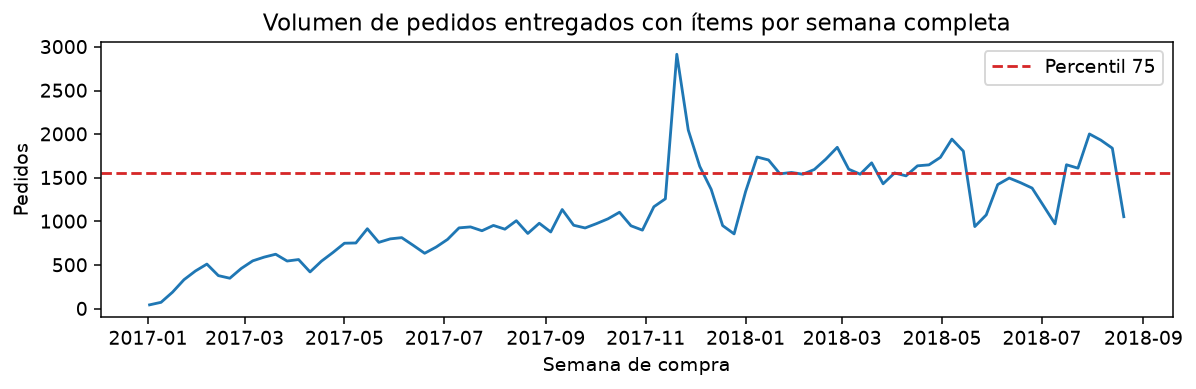

In [7]:
import numpy as np
import matplotlib.pyplot as plt

e = pedidos_enriquecidos
compra = pd.to_datetime(e["order_purchase_timestamp"], errors="coerce", format="mixed")
entrega = pd.to_datetime(e["order_delivered_customer_date"], errors="coerce", format="mixed")
promesa = pd.to_datetime(e["order_estimated_delivery_date"], errors="coerce", format="mixed")
aprobacion = pd.to_datetime(e["order_approved_at"], errors="coerce", format="mixed")
despacho = pd.to_datetime(e["order_delivered_carrier_date"], errors="coerce", format="mixed")

e["semana_compra"] = compra.dt.to_period("W-SUN").dt.start_time
en_poblacion = e["en_poblacion"]
volumen = e.loc[en_poblacion].groupby("semana_compra").size()
semanas_completas = volumen.loc[
    (volumen.index >= pd.Timestamp("2017-01-01"))
    & (volumen.index + pd.Timedelta(days=6) <= pd.Timestamp("2018-08-31"))
]
umbral = semanas_completas.quantile(0.75)
e["alta_demanda"] = e["semana_compra"].map(semanas_completas.ge(umbral)).astype("boolean")

fechas_validas = (
    e["order_status"].eq("delivered")
    & entrega.ge(compra)
    & promesa.dt.normalize().ge(compra.dt.normalize())
    & ~aprobacion.lt(compra)
    & ~despacho.lt(compra)
    & ~despacho.lt(aprobacion)
    & ~entrega.lt(despacho)
)
e["entrega_tardia"] = entrega.dt.normalize().gt(promesa.dt.normalize()).astype("boolean").where(fechas_validas)

poblacion_enriquecida = e.loc[en_poblacion].copy()
ratio = poblacion_enriquecida["flete_pct_mercaderia"]
print(ratio.describe(percentiles=[.25, .5, .75, .95]).round(2).to_string())
print("Pedidos con flete superior al valor de mercadería:", ratio.gt(100).sum())
print(f"Semanas de alta demanda: {semanas_completas.ge(umbral).sum()} de {len(semanas_completas)}; umbral: {umbral:.0f} pedidos")
print("Pedidos sin semana clasificable:", poblacion_enriquecida["alta_demanda"].isna().sum())
print("Entregas tardías, puntuales o desconocidas:")
print(poblacion_enriquecida["entrega_tardia"].value_counts(dropna=False).to_string())

fig_features, ax = plt.subplots(figsize=(9, 3))
ax.plot(semanas_completas.index, semanas_completas.values, color="tab:blue")
ax.axhline(umbral, color="tab:red", linestyle="--", label="Percentil 75")
ax.set(title="Volumen de pedidos entregados con ítems por semana completa",
       ylabel="Pedidos", xlabel="Semana de compra")
ax.legend()
fig_features.tight_layout()
plt.show()

**Interpretación.** La mediana del flete relativo es 22,44 % y el percentil 95 es 83,89 %. Hay 3.069 pedidos por encima de 100 % y el máximo es 2.144,71 %. Conservamos esos valores para el análisis descriptivo y usamos la mediana para limitar su influencia. El gráfico muestra que el volumen semanal creció durante el período, por lo que la etiqueta de alta demanda también refleja la evolución de la plataforma. Quedaron 1.377 pedidos con atraso desconocido y 116 compras sin semana clasificable.

## 7. Respuestas a las preguntas

**Flete.** Comparamos la mediana del ratio entre destinos metropolitanos y no metropolitanos del mismo estado. Mostramos conteos y exigimos al menos 30 pedidos por grupo para limitar la influencia de muestras pequeñas. El corte es descriptivo y las diferencias pueden reflejar la composición de los pedidos.

**Atrasos.** Comparamos tasas municipales entre semanas de alta demanda y normales. Exigimos al menos 30 pedidos con fechas válidas por grupo y expresamos la diferencia en puntos porcentuales. Ese mínimo estabiliza la lectura descriptiva, pero las tasas siguen sujetas a variación y no identifican un efecto causal.

                flete_no_metro  flete_metro  n_no_metro  n_metro  diferencia_pp
customer_state                                                                 
TO                       43.51        31.92       112.0    161.0         -11.59
RO                       43.96        35.83       128.0    113.0          -8.13
SE                       38.87        32.35        95.0    236.0          -6.52
PA                       38.67        32.17       335.0    599.0          -6.50
PB                       41.52        35.23        51.0    463.0          -6.29
RN                       34.87        29.98       185.0    283.0          -4.89
MA                       41.90        37.06       305.0    405.0          -4.84
CE                       34.09        31.02       399.0    870.0          -3.06
RS                       26.81        24.45      2478.0   2846.0          -2.35
SP                       19.94        18.57      7957.0  32434.0          -1.37
PR                       25.68        24

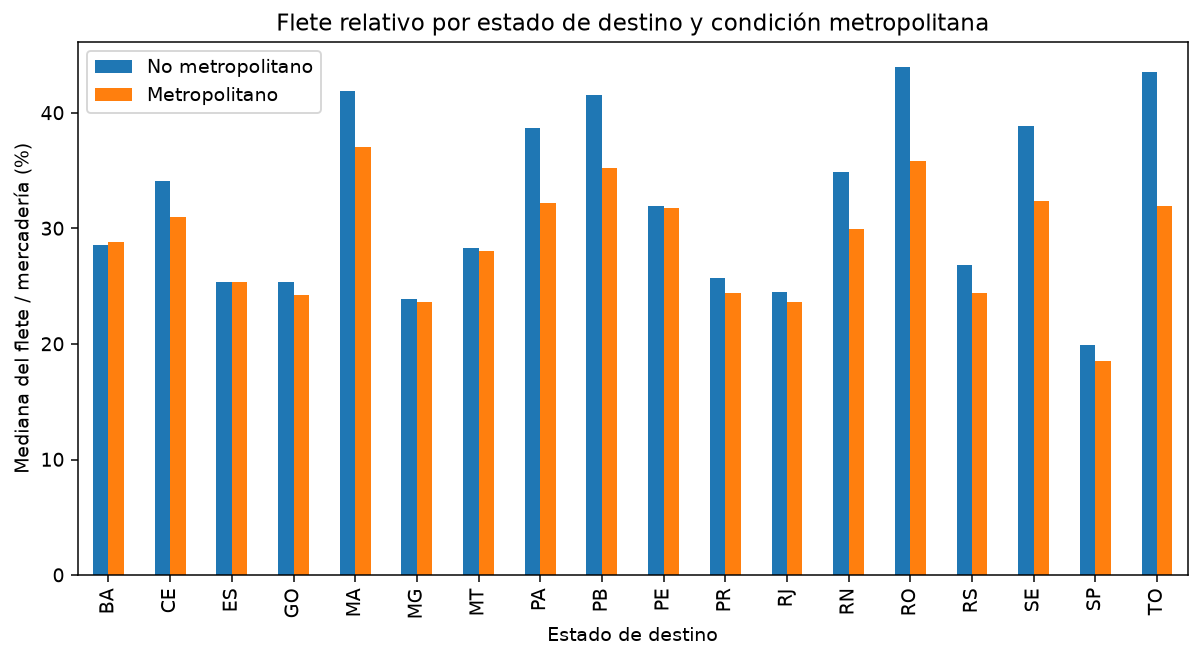

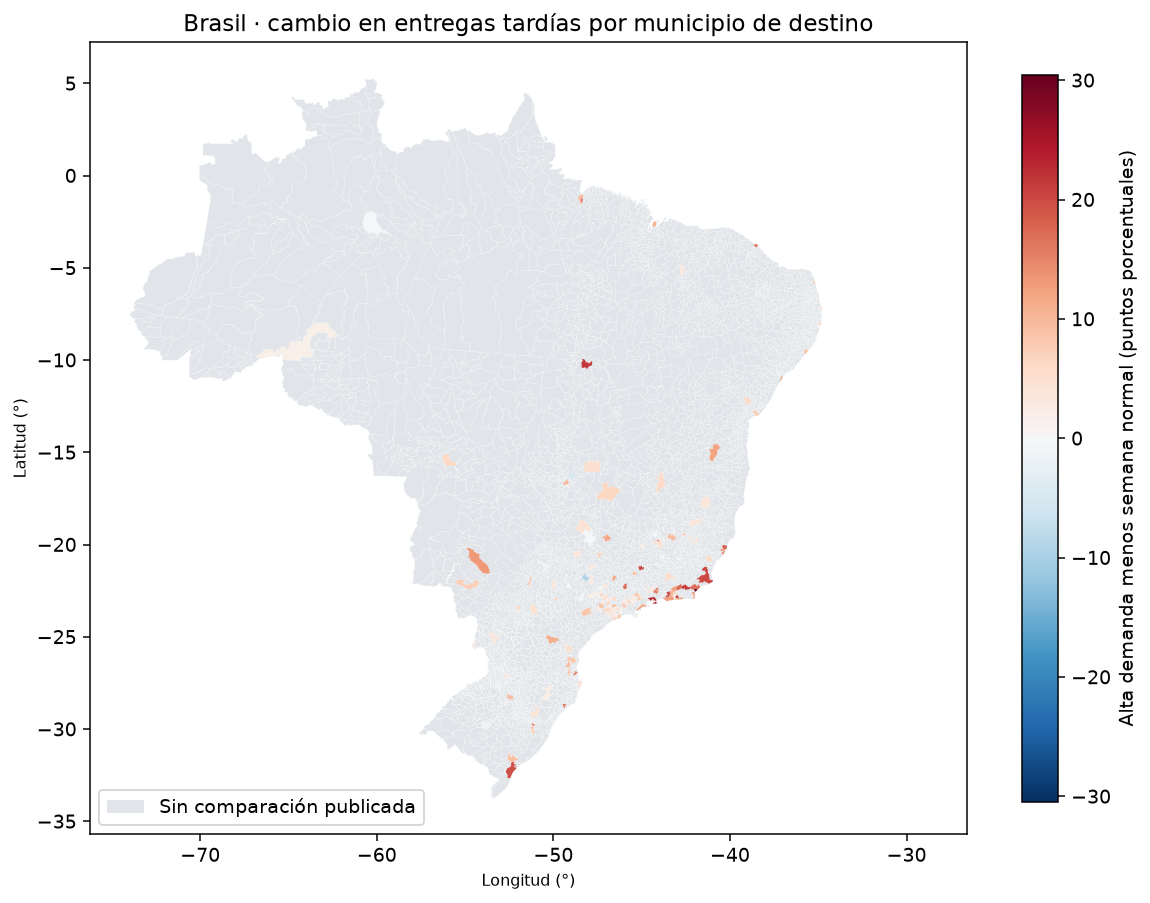

In [8]:
p_geo = poblacion_enriquecida.dropna(subset=["es_metropolitano", "flete_pct_mercaderia"])
flete_estado = p_geo.groupby(["customer_state", "es_metropolitano"])["flete_pct_mercaderia"].agg(
    mediana="median", pedidos="size"
).unstack()
flete_estado = flete_estado.loc[flete_estado["pedidos"].ge(30).all(axis=1)]
flete_estado.columns = ["flete_no_metro", "flete_metro", "n_no_metro", "n_metro"]
flete_estado["diferencia_pp"] = flete_estado["flete_metro"] - flete_estado["flete_no_metro"]
print(flete_estado.round(2).sort_values("diferencia_pp").to_string())

p_atrasos = poblacion_enriquecida.dropna(subset=["codigo_municipio", "alta_demanda", "entrega_tardia"])
atrasos_municipio = p_atrasos.groupby(["codigo_municipio", "alta_demanda"])["entrega_tardia"].agg(
    tasa="mean", pedidos="size"
).unstack()
atrasos_municipio = atrasos_municipio.loc[atrasos_municipio["pedidos"].ge(30).all(axis=1)]
atrasos_municipio.columns = ["tasa_normal", "tasa_alta", "n_normal", "n_alta"]
atrasos_municipio["diferencia_pp"] = 100 * (atrasos_municipio["tasa_alta"] - atrasos_municipio["tasa_normal"])
ranking_atrasos = atrasos_municipio.join(municipios.set_index("codigo_municipio")["municipio_ibge"])
ranking_atrasos = ranking_atrasos.sort_values("diferencia_pp", ascending=False)
print(ranking_atrasos.head(10).round(3).to_string())

fig_flete, ax = plt.subplots(figsize=(9, 5))
flete_estado[["flete_no_metro", "flete_metro"]].rename(
    columns={"flete_no_metro": "No metropolitano", "flete_metro": "Metropolitano"}
).plot.bar(ax=ax)
ax.set(title="Flete relativo por estado de destino y condición metropolitana",
       ylabel="Mediana del flete / mercadería (%)", xlabel="Estado de destino")
fig_flete.tight_layout()
plt.show()

from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

mapa = municipios.join(atrasos_municipio[["diferencia_pp"]], on="codigo_municipio")
con_tasa = mapa["diferencia_pp"].notna()
extremo = max(mapa.loc[con_tasa, "diferencia_pp"].abs().max(), 1)
escala = TwoSlopeNorm(vmin=-extremo, vcenter=0, vmax=extremo)
fig_mapa, ax = plt.subplots(figsize=(9, 8))
mapa.plot(ax=ax, color="#e1e5e9", edgecolor="white", linewidth=.08)
mapa.loc[con_tasa].plot(ax=ax, column="diferencia_pp", cmap="RdBu_r", norm=escala)
fig_mapa.colorbar(ScalarMappable(norm=escala, cmap="RdBu_r"), ax=ax, shrink=.7,
                  label="Alta demanda menos semana normal (puntos porcentuales)")
ax.legend(handles=[Patch(facecolor="#e1e5e9", label="Sin comparación publicada")], loc="lower left")
ax.set(title="Brasil · cambio en entregas tardías por municipio de destino",
       xlabel="Longitud (°)", ylabel="Latitud (°)")
fig_mapa.tight_layout()
plt.show()

**Interpretación del flete.** En 16 de 18 estados comparables, la mediana fue menor en destinos metropolitanos. En São Paulo fue 18,57 % frente a 19,94 %. La comparación ayuda a seleccionar zonas para revisar tarifas. Peso, origen del vendedor y composición de la compra son explicaciones posibles que quedan por evaluar.

**Interpretación del mapa.** Rio das Ostras pasó de 6,25 % de entregas tardías en semanas normales (80 pedidos) a 36,73 % en semanas de alta demanda (49 pedidos), una diferencia de 30,48 puntos porcentuales. El gris marca municipios sin comparación por falta de observaciones suficientes en uno o ambos grupos. El mapa permite priorizar una revisión de plazos. El crecimiento de la plataforma, la estacionalidad y cambios en los pedidos también pueden influir.

#### Contraste con la predicción inicial.

Los resultados respaldan la predicción. El flete relativo mediano fue menor en los destinos metropolitanos en 16 de 18 estados comparables. En Río de Janeiro, los atrasos aumentaron 30,48 puntos porcentuales en Rio das Ostras y 23,26 en Angra dos Reis durante las semanas de alta demanda. Estas diferencias muestran que ambos indicadores revelan variación dentro de un mismo estado.

## 8. Aporte de las variables

**Decisión y justificación.** Usamos la entrega tardía como resultado y comparamos flete relativo, volumen alto y condición metropolitana. Spearman mide asociación monotónica y conserva el signo. La información mutua mide dependencia en bits y permite detectar asociaciones que no siguen una dirección única. Para calcularla agrupamos el ratio en cuartiles.

**Límite.** Los métodos son descriptivos, se calculan sobre los mismos casos completos y no ajustan por otros factores. La discretización puede ocultar diferencias dentro de cada cuartil. El indicador de atraso se evalúa como resultado y sus componentes se excluyen de los predictores.

In [9]:
variables = ["flete_pct_mercaderia", "alta_demanda", "es_metropolitano"]
evaluacion = poblacion_enriquecida[variables + ["entrega_tardia"]].dropna().astype(float)
spearman = evaluacion.rank().corr()["entrega_tardia"].loc[variables]

mi = {}
for variable in variables:
    valores = evaluacion[variable]
    grupos = pd.qcut(valores, 4, duplicates="drop") if variable == "flete_pct_mercaderia" else valores
    conjunta = pd.crosstab(grupos, evaluacion["entrega_tardia"], normalize="all").to_numpy()
    independiente = conjunta.sum(axis=1, keepdims=True) * conjunta.sum(axis=0, keepdims=True)
    positivas = conjunta > 0
    mi[variable] = (conjunta[positivas] * np.log2(conjunta[positivas] / independiente[positivas])).sum()

importancia = pd.DataFrame({"Spearman": spearman, "Información mutua (bits)": pd.Series(mi)})
print(f"Pedidos comparables: {len(evaluacion):,}")
print(importancia.round(6).to_string())

Pedidos comparables: 94,370
                      Spearman  Información mutua (bits)
flete_pct_mercaderia  0.003647                  0.000023
alta_demanda          0.114584                  0.009279
es_metropolitano      0.011738                  0.000100


**Interpretación.** Ambos métodos ordenan las variables igual. Alta demanda tiene la mayor asociación con atraso (Spearman ≈ 0,115; información mutua ≈ 0,0093 bits), aunque es modesta. La condición metropolitana y el ratio aportan poca información marginal sobre atraso. Se conservan para el análisis geográfico y de flete, y quedan como candidatos de baja prioridad para un modelo de atrasos.

## 9. Controles y pruebas de fallo

**Decisión y justificación.** Comprobamos que el ratio sea finito, no negativo y coherente con su fórmula. Para el cruce, verificamos la unicidad de pedidos, que todo código asignado exista en IBGE, que su estado coincida y que la clasificación reproduzca el catálogo de regiones metropolitanas. Inyectamos dos fallos en copias de la tabla para verificar que los controles los detectan.

**Límite.** Una ubicación equivocada dentro del mismo estado puede pasar los controles. El ratio también puede pasar si los importes de origen son incorrectos pero coherentes entre sí.

In [10]:
def controlar_ratio(df):
    valor = df["facturacion"]
    esperado = 100 * df["costo_envio"] / valor.where(valor.gt(0))
    ratio = df["flete_pct_mercaderia"]
    assert np.isfinite(ratio.dropna()).all() and ratio.dropna().ge(0).all(), "Ratio no finito o negativo"
    assert np.allclose(ratio, esperado, equal_nan=True), "Ratio incompatible con los importes"

def controlar_espacio(df):
    codigo = df["codigo_municipio"]
    asignado = codigo.notna()
    assert len(df) == len(pedidos) and df["order_id"].is_unique, "Cambió el grano de pedido"
    assert asignado.equals(df["estado_cruce"].eq("asignado")), "Estado del cruce inconsistente"
    assert codigo[asignado].isin(municipios["codigo_municipio"]).all(), "Código municipal desconocido"
    assert codigo[asignado].str[:2].map(siglas_uf).eq(df.loc[asignado, "customer_state"]).all(), "Estado incompatible"
    esperado = codigo.isin(codigos_rm).astype("boolean").where(asignado)
    assert esperado.equals(df["es_metropolitano"]), "Clasificación metropolitana incompatible"

controlar_ratio(e)
controlar_espacio(e)

fila = e.index[e["codigo_municipio"].notna()][0]
for nombre, columna, valor, control in [
    ("flete negativo", "flete_pct_mercaderia", -1, controlar_ratio),
    ("municipio inexistente", "codigo_municipio", "0000000", controlar_espacio),
]:
    prueba = e.copy()
    prueba.loc[fila, columna] = valor
    try:
        control(prueba)
    except AssertionError as error:
        print(f"{nombre}: detectado ({error})")
    else:
        raise AssertionError(f"El control no detectó {nombre}")

flete negativo: detectado (Ratio no finito o negativo)
municipio inexistente: detectado (Código municipal desconocido)


## 10. Esquema y exportación

**Decisión y justificación.** El GeoPackage conserva una fila por pedido, todas las columnas curadas del Caso 1 y los campos documentados abajo. Exportamos los puntos aproximados en EPSG:4326 y conservamos geometrías nulas cuando falta la coordenada. Los atributos municipales siguen vacíos si la asignación fue incierta.

| Campos nuevos | Qué representan y de dónde vienen |
|---|---|
| `customer_zip_code_prefix` | Prefijo postal de cinco dígitos en el CSV original de clientes. |
| `latitud`, `longitud`, `geometry` | Punto mediano por prefijo y estado en la geolocalización curada de Olist. |
| `codigo_municipio`, `municipio_ibge`, `estado_cruce` | Código, nombre y resultado de asignación a los polígonos del IBGE 2018. |
| `es_metropolitano` | Pertenencia administrativa a una RM del IBGE en junio de 2018. |
| `semana_compra`, `alta_demanda` | Lunes de compra y condición según el volumen semanal de Olist. |
| `entrega_tardia` | Indicador calculado a partir de las fechas del pedido. |

**Límite.** El GeoPackage reúne ubicaciones aproximadas e incluye pedidos fuera de población para mantener la trazabilidad. Los indicadores requieren filtrar por `en_poblacion` y por la disponibilidad de los campos de cada pregunta.

In [11]:
salida = Path("data/enriched")
salida.mkdir(parents=True, exist_ok=True)
ruta_gpkg = salida / "pedidos_enriquecidos.gpkg"
geometria = gpd.GeoSeries([None] * len(e), index=e.index, crs="EPSG:4326")
geometria.loc[con_coordenadas] = gpd.points_from_xy(
    e.loc[con_coordenadas, "longitud"], e.loc[con_coordenadas, "latitud"]
)
gdf_enriquecido = gpd.GeoDataFrame(e, geometry=geometria, crs="EPSG:4326")
gdf_enriquecido.to_file(ruta_gpkg, layer="pedidos", driver="GPKG", index=False)
releido = gpd.read_file(ruta_gpkg, layer="pedidos")
assert len(releido) == len(pedidos) and releido["order_id"].is_unique
assert releido.crs.to_epsg() == 4326
assert releido.geometry.notna().sum() == con_coordenadas.sum()
print(f"{ruta_gpkg}: {len(releido):,} pedidos, {len(releido.columns)} campos")

data/enriched/pedidos_enriquecidos.gpkg: 99,441 pedidos, 30 campos


## 11. Cierre

El enriquecimiento permite comparar el peso del flete dentro de un estado y localizar municipios donde la puntualidad cambia en semanas de alta demanda. Los resultados pueden orientar revisiones de tarifas y promesas de entrega. La precisión postal, el corte administrativo fijo, la cobertura de fechas y la ausencia de ajustes por origen, peso o composición limitan estas comparaciones.

Para producción se necesitaría automatizar y versionar las fuentes, medir periódicamente cobertura y errores de asignación, y validar estos patrones en ventanas posteriores. El umbral de demanda se calculó descriptivamente con todo el período y debería estimarse con datos históricos disponibles al momento de aplicación.

## Declaración de uso de IA

Usamos **Claude Code (Opus 5.5 y Sonnet 5.5)** y **Codex (OpenAI, GPT-6)** como apoyo durante el trabajo.

- **Interpretación e investigación.** Consultamos a la IA para entender qué representaban las tablas, cómo se relacionaban y qué podían significar algunos patrones que observamos en los datos. También la usamos para orientar la búsqueda de contexto sobre el dataset.
- **Implementación y verificación.** Como equipo primero pensamos en cómo resolver cada problema y qué necesitábamos en cada etapa. Le pedimos a la IA que implementara las celdas en base a los requerimientos que obtuvimos tras entender el problema, esto para cumplir con los pasos requeridos, la curación y los controles. Ejecutamos las celdas, revisamos sus resultados y corregimos el código cuando fue necesario y realizamos interpretaciones correspondientes.
- **Revisión de la entrega.** Le pedimos a la IA que comparara el estado del notebook con la consigna y la devolución docente para identificar puntos pendientes. Revisamos esas observaciones y decidimos qué cambios incorporar.
- **Redacción del informe.** Usamos la IA para revisar la redacción y mejorar la claridad del informe.